In [1]:
import pandas as pd
from pathlib import Path

# Assign path
ROOT = Path.cwd() / "estonia-exam-gap"
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"

In [2]:
!git clone 'https://github.com/valpar/estonia-exam-gap.git'

Cloning into 'estonia-exam-gap'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (81/81), done.
remote: Compressing objects: 100% (57/57), done.
remote: Total 81 (delta 35), reused 60 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (81/81), 1.76 MiB | 23.44 MiB/s, done.
Resolving deltas: 100% (35/35), done.


# Y : Target – Broad Maths Exam Results

Ideal Format (Columns)

school_name, academic_year, average_score, cohort_size

One row per school per school year. Source: Haridussilm riigieksamid export grouped by school
(2020/21–2024/25, full-time gymnasium graduates only). Broad maths (lai) only.

In [3]:
# Load the raw export. header=2: the first two rows are Power BI filter notes
df_raw_exam = pd.read_excel(RAW / 'riigieksam_math_2021-2025_by_school_location.xlsx', header=2)
df_raw_exam.info()
df_raw_exam.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1419 entries, 0 to 1418
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Õppeaasta                  1419 non-null   object 
 1   Eksam                      1419 non-null   object 
 2   Õppeasutus                 1419 non-null   object 
 3   Maakond                    1419 non-null   object 
 4   Kohalik omavalitsus        1419 non-null   object 
 5   Õppeasutuse tüüp           1419 non-null   object 
 6   Max võimalik punktide arv  1419 non-null   int64  
 7   Sooritajate arv            1419 non-null   int64  
 8   Keskmine                   1240 non-null   float64
 9   Keskmine (%)               1240 non-null   float64
 10  St. Hälve                  1240 non-null   float64
 11  Mediaan                    1240 non-null   float64
 12  AUP                        1240 non-null   float64
 13  ÜUP                        1240 non-null   float

,Õppeaasta,Eksam,Õppeasutus,Maakond,Kohalik omavalitsus,Õppeasutuse tüüp,Max võimalik punktide arv,Sooritajate arv,Keskmine,Keskmine (%),St. Hälve,Mediaan,AUP,ÜUP,Min,Min punktide saajaid,Max,Max punktide saajaid,B2 (%)
0,2024/25,Matemaatika (riigieksam) (kitsas),Abja Gümnaasium,Viljandi maakond,Mulgi vald,põhikool või gümnaasium,100,13,35.153846,0.351538,19.398652,28.0,24.608619,45.699073,14.0,NaN,77.0,NaN,NaN
1,2024/25,Matemaatika (riigieksam) (kitsas),Antsla Gümnaasium,Võru maakond,Antsla vald,põhikool või gümnaasium,100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024/25,Matemaatika (riigieksam) (kitsas),Audentese Spordigümnaasium,Harju maakond,Tallinn,põhikool või gümnaasium,100,15,36.400000,0.364000,16.565023,37.0,28.016942,44.783058,6.0,NaN,72.0,NaN,NaN
3,2024/25,Matemaatika (riigieksam) (kitsas),Audentese Spordigümnaasiumi Otepää filiaal,Valga maakond,Otepää vald,põhikool või gümnaasium,100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024/25,Matemaatika (riigieksam) (kitsas),August Kitzbergi nimeline Gümnaasium,Viljandi maakond,Mulgi vald,põhikool või gümnaasium,100,7,34.142857,0.341429,18.836388,25.0,20.188665,48.097049,19.0,NaN,69.0,NaN,NaN


In [4]:
# To check what exams are in the files
df_raw_exam['Eksam'].value_counts()

,count
Eksam,
Matemaatika (riigieksam) (kitsas),711
Matemaatika (riigieksam) (lai),708


In [5]:
# To filter out narrow(kitsas) maths boolean mask
df_raw_exam['Eksam'].str.contains('lai')

,Eksam
0,False
1,False
2,False
3,False
4,False
...,...
1414,True
1415,True
1416,True
1417,True


In [6]:
# Keep broad maths only; .copy() makes an independent table so later changes don't affect the raw data
df_exam = df_raw_exam[df_raw_exam['Eksam'].str.contains('lai')].copy()
df_exam.shape

(708, 19)

In [7]:
# Check the filter caught only broad maths
df_exam['Eksam'].value_counts()

,count
Eksam,
Matemaatika (riigieksam) (lai),708


In [8]:
# Keep only the four columns we need
df_exam = df_exam[['Õppeaasta', 'Õppeasutus', 'Sooritajate arv', 'Keskmine']]
df_exam.head()

,Õppeaasta,Õppeasutus,Sooritajate arv,Keskmine
141,2024/25,Abja Gümnaasium,5,25.600000
142,2024/25,Antsla Gümnaasium,19,28.210526
143,2024/25,Audentese Spordigümnaasium,29,38.965517
144,2024/25,Audentese Spordigümnaasiumi Otepää filiaal,15,40.533333
145,2024/25,August Kitzbergi nimeline Gümnaasium,5,49.000000


In [9]:
# Keep the four columns we need and give them English names matching the other tables
df_exam = df_exam.rename(columns={
    'Õppeaasta': 'academic_year',
    'Õppeasutus': 'school_name',
    'Sooritajate arv': 'cohort_size',
    'Keskmine': 'average_score'
})
df_exam.head()

,academic_year,school_name,cohort_size,average_score
141,2024/25,Abja Gümnaasium,5,25.600000
142,2024/25,Antsla Gümnaasium,19,28.210526
143,2024/25,Audentese Spordigümnaasium,29,38.965517
144,2024/25,Audentese Spordigümnaasiumi Otepää filiaal,15,40.533333
145,2024/25,August Kitzbergi nimeline Gümnaasium,5,49.000000


In [10]:
# Check the school years in the data
df_exam['academic_year'].unique()

array(['2024/25', '2023/24', '2022/23', '2021/22', '2020/21'],
      dtype=object)

In [11]:
# Count empty cells in each column:
# .isna() marks every empty cell as True, .sum() adds them up per column (True = 1, False = 0)
df_exam.isna().sum()

,0
academic_year,0
school_name,0
cohort_size,0
average_score,82


In [12]:
# To check why are scores missing, for rows with no score, count the cohort sizes
df_exam.loc[df_exam['average_score'].isna(), 'cohort_size'].value_counts().sort_index()

,count
cohort_size,
1,28
2,14
3,20
4,20


In [13]:
# Remove rows with no score
rows_before = len(df_exam)
df_exam = df_exam.dropna(subset=['average_score'])
print(f"Removed {rows_before - len(df_exam)} rows with hidden scores, {len(df_exam)} rows left")

Removed 82 rows with hidden scores, 626 rows left


In [14]:
df_target = df_exam[['school_name', 'academic_year', 'average_score', 'cohort_size']].copy()

# Mapping between academic and exam year ex: '2020/21' -> 2021
df_target['school_name'] = df_target['school_name'].str.strip()
df_target['exam_year'] = df_target['academic_year'].str.slice(0, 4).astype(int) + 1

# Sort the table with ['school_name', 'exam_year'] pairs
df_target = df_target[['school_name', 'exam_year', 'academic_year', 'average_score', 'cohort_size']]
df_target = df_target.sort_values(['school_name', 'exam_year']).reset_index(drop=True)
df_target.head()

,school_name,exam_year,academic_year,average_score,cohort_size
0,''Eduson'' kool,2023,2022/23,28.833333,6
1,Abja Gümnaasium,2022,2021/22,40.000000,5
2,Abja Gümnaasium,2024,2023/24,19.833333,6
3,Abja Gümnaasium,2025,2024/25,25.600000,5
4,Antsla Gümnaasium,2021,2020/21,29.600000,10


In [15]:
# each school should appear only once per school year.
# .duplicated() marks repeated school + year combinations as True; .sum() counts them
df_target.duplicated(subset=['school_name', 'academic_year']).sum()

np.int64(0)

In [16]:
# Scores must be between 0 and 100, and cohort sizes at least 5.
df_target.describe()

,exam_year,average_score,cohort_size
count,626.000000,626.000000,626.000000
mean,2023.011182,51.664966,35.308307
std,1.416995,17.730181,34.370348
min,2021.000000,3.600000,5.000000
25%,2022.000000,37.922144,12.000000
50%,2023.000000,51.708108,23.000000
75%,2024.000000,64.334139,45.000000
max,2025.000000,92.350000,175.000000


In [17]:
# how many schools, and how many rows per school year
print("Number of schools:", df_target['school_name'].nunique())
df_target['academic_year'].value_counts().sort_index()

Number of schools: 155


,count
academic_year,
2020/21,123
2021/22,127
2022/23,124
2023/24,124
2024/25,128


In [18]:
# Create the processed folder if it doesn't exist yet (exist_ok=True: no error if it already exists)
PROCESSED.mkdir(parents=True, exist_ok=True)

# Save as CSV; index=False stops pandas writing the row numbers 0, 1, 2 ... as an extra column
df_target.to_csv(PROCESSED / 'target_broad_math_2021-2025.csv', index=False)

# Check: read the file back and confirm it has the same size as the table (expected: (626, 4))
pd.read_csv(PROCESSED / 'target_broad_math_2021-2025.csv').shape

(626, 5)

# X1 : Qualified Teacher Ratio

Ideal Format (Columns)

school_name,
exam_year,
estonian_proficiency_ratio,
teaching_qualification_ratio,

In [19]:
df_raw_qualified_teacher = pd.read_excel(ROOT/RAW/'haridussilm_qualified_teachers_2021-2025_by_school.xlsx', header=2)
df_raw_qualified_teacher.head()

,Indikaator,Õppeasutus/KOV/Eesti,'Date'[Year],Väärtused
0,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2021,100
1,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2022,100
2,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2023,100
3,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2024,"95,5"
4,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2025,100


In [20]:
# Examine the columns
df_raw_qualified_teacher.columns

Index(['Indikaator', 'Õppeasutus/KOV/Eesti', ''Date'[Year]', 'Väärtused'], dtype='object')

In [21]:
# Translation of estonian column names to english
df_raw_qualified_teacher = df_raw_qualified_teacher.rename(columns={
    "Õppeasutus/KOV/Eesti": "school",
    "'Date'[Year]": "year",
    "Indikaator": "indicator",
    "Väärtused": "percentage"
})
df_raw_qualified_teacher.head()

,indicator,school,year,percentage
0,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2021,100
1,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2022,100
2,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2023,100
3,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2024,"95,5"
4,Eesti keele oskuse nõuetele vastavad õpetajad ...,Abja Gümnaasium,2025,100


In [22]:
# Convert percentatge to decimal values
df_raw_qualified_teacher['percentage'] = df_raw_qualified_teacher['percentage'].astype(str).str.replace(',', '.').astype(float)

# Pivot the table to mathcing ideal format definted above
df_raw_qualified_teacher_wide = pd.pivot_table(
    df_raw_qualified_teacher,
    index=['school', 'year'],
    columns='indicator',
    values='percentage'
).reset_index()

# Rename the columns
df_raw_qualified_teacher_wide.columns = [
    'school_name',
    'exam_year',
    'estonian_proficiency_ratio',
    'teaching_qualification_ratio'
]

# strip the school name and conver the type of exam year
df_raw_qualified_teacher_wide['school_name'] = df_raw_qualified_teacher_wide['school_name'].str.strip()
df_raw_qualified_teacher_wide['exam_year'] = df_raw_qualified_teacher_wide['exam_year'].astype(int)
df_raw_qualified_teacher_wide.head()

,school_name,exam_year,estonian_proficiency_ratio,teaching_qualification_ratio
0,''Eduson'' kool,2021,80.0,100.0
1,''Eduson'' kool,2022,68.8,100.0
2,''Eduson'' kool,2023,60.0,100.0
3,''Eduson'' kool,2024,85.7,100.0
4,''Eduson'' kool,2025,100.0,100.0


# X2 : State of the School (State or Municipal)

Ideal Format (Columns)

school_name, ownership, academic_year

In [23]:
# Load schools ran by state
df_raw_school_state = pd.read_excel(ROOT/RAW/'/content/estonia-exam-gap/data/raw/haridussilm_students_2021-2025_state.xlsx', header=2)
df_raw_school_state.info()
df_raw_school_state.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 163 entries, 0 to 162
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   KOV/Õppeasutus   163 non-null    object
 1   Õppeasutus       163 non-null    object
 2   Õppurite arv ap  163 non-null    int64 
 3   Õppeaasta        163 non-null    object
dtypes: int64(1), object(3)
memory usage: 5.2+ KB


/usr/local/lib/python3.13/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,KOV/Õppeasutus,Õppeasutus,Õppurite arv ap,Õppeaasta
0,Haapsalu linn,Läänemaa Ühisgümnaasium,258,2020/21
1,Haapsalu linn,Läänemaa Ühisgümnaasium,272,2021/22
2,Haapsalu linn,Läänemaa Ühisgümnaasium,283,2022/23
3,Haapsalu linn,Läänemaa Ühisgümnaasium,260,2023/24
4,Haapsalu linn,Läänemaa Ühisgümnaasium,268,2024/25


In [24]:
# Load schools ran by municipal
df_raw_school_municipal = pd.read_excel(ROOT/RAW/'/content/estonia-exam-gap/data/raw/haridussilm_students_2021-2025_municipal.xlsx', header=2)
df_raw_school_municipal.info()
df_raw_school_municipal.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 631 entries, 0 to 630
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   KOV/Õppeasutus   631 non-null    object
 1   Õppeasutus       631 non-null    object
 2   Õppurite arv ap  631 non-null    int64 
 3   Õppeaasta        631 non-null    object
dtypes: int64(1), object(3)
memory usage: 19.8+ KB


,KOV/Õppeasutus,Õppeasutus,Õppurite arv ap,Õppeaasta
0,Alutaguse vald,Iisaku Põhikool,48,2020/21
1,Alutaguse vald,Iisaku Põhikool,50,2021/22
2,Alutaguse vald,Iisaku Põhikool,31,2022/23
3,Alutaguse vald,Iisaku Põhikool,20,2023/24
4,Alutaguse vald,Iisaku Põhikool,7,2024/25


In [25]:
# Assigne the ownership value directly
df_raw_school_state['ownership'] = 'state'
df_raw_school_municipal['ownership'] = 'municipal'

df_raw_school_combined = pd.concat([df_raw_school_municipal, df_raw_school_state], ignore_index=True)
df_raw_school_combined.info()
df_raw_school_combined.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 794 entries, 0 to 793
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   KOV/Õppeasutus   794 non-null    object
 1   Õppeasutus       794 non-null    object
 2   Õppurite arv ap  794 non-null    int64 
 3   Õppeaasta        794 non-null    object
 4   ownership        794 non-null    object
dtypes: int64(1), object(4)
memory usage: 31.1+ KB


,KOV/Õppeasutus,Õppeasutus,Õppurite arv ap,Õppeaasta,ownership
0,Alutaguse vald,Iisaku Põhikool,48,2020/21,municipal
1,Alutaguse vald,Iisaku Põhikool,50,2021/22,municipal
2,Alutaguse vald,Iisaku Põhikool,31,2022/23,municipal
3,Alutaguse vald,Iisaku Põhikool,20,2023/24,municipal
4,Alutaguse vald,Iisaku Põhikool,7,2024/25,municipal


In [26]:
df_raw_school_combined = df_raw_school_combined[['Õppeasutus', 'ownership', 'Õppeaasta']].copy()
df_raw_school_combined.columns = ['school_name', 'ownership', 'academic_year']

# Map academic year to exam year
df_raw_school_combined['school_name'] = df_raw_school_combined['school_name'].str.strip()
df_raw_school_combined['exam_year'] = df_raw_school_combined['academic_year'].str.slice(0, 4).astype(int) + 1

# Keep only 2021 to 2025
df_raw_school_combined = (
    df_raw_school_combined[df_raw_school_combined['exam_year'].between(2021, 2025)]
    [['school_name', 'exam_year', 'academic_year', 'ownership']]
    .drop_duplicates(subset=['school_name', 'exam_year'])
    .reset_index(drop=True)
)
df_raw_school_combined.head()

,school_name,exam_year,academic_year,ownership
0,Iisaku Põhikool,2021,2020/21,municipal
1,Iisaku Põhikool,2022,2021/22,municipal
2,Iisaku Põhikool,2023,2022/23,municipal
3,Iisaku Põhikool,2024,2023/24,municipal
4,Iisaku Põhikool,2025,2024/25,municipal




# X3 : Distance to Hubs

Ideal Format (Columns)

school_name, longitude, latitude, distance_nearest_hub



In [27]:
# Install tools for distance calculation
!pip install geopandas shapley pyrosm

# Download latest osm data for estonia
!wget https://download.geofabrik.de/europe/estonia-latest.osm.pbf

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of shapley to determine which version is compatible with other requirements. This could take a while.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 22.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 71.0 MB/s  0:00:00
  Created wheel for shapley: filename=shapley-1.0.2-py3-none-any.whl size=7088 sha256=3bf02d13ee1c647157bb57cea69d845b3425e390d8658cad021e52b7225b2149
  Stored in directory: /root/.cache/pip/wheels/b7/14/2e/d66bdb9f10edb1b1746689bb02b97402b079c93654533ea2db
Successfully built shapley
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pyrosm]
--2026-11-

In [28]:
# Extract a school list
df_raw_school_list = df_raw_school_combined[['school_name']].drop_duplicates()
df_raw_school_list.info()
df_raw_school_list.head()

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 0 to 661
Data columns (total 1 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   school_name  148 non-null    object
dtypes: object(1)
memory usage: 2.3+ KB


,school_name
0,Iisaku Põhikool
5,Kehra Gümnaasium
10,Antsla Gümnaasium
15,Elva Gümnaasium
20,Rõngu Keskkool


In [29]:
# Fetch geo location of all school from estonia latest Open Stree Map data
from pyrosm import OSM

osm = OSM("/content/estonia-latest.osm.pbf")
schools = osm.get_pois(
    custom_filter={
        "amenity": ["school"]
    }
)
schools = schools[schools["name"].notna()]

# Geo data transformation (From help of AI)
schools_projected = schools.to_crs(epsg=3301)
centroids = schools_projected.geometry.centroid
centroids_wgs84 = centroids.to_crs(epsg=4326)

schools["longitude"] = centroids_wgs84.x
schools["latitude"] = centroids_wgs84.y

df_raw_schools_coordination = schools[["name", "latitude", "longitude"]].copy()
df_raw_schools_coordination.columns = ["school_name", "latitude", "longitude"]

# Strip the school name and further filter out the duplicate
df_raw_schools_coordination["school_name"] = df_raw_schools_coordination["school_name"].str.strip()
df_raw_schools_coordination = df_raw_schools_coordination.drop_duplicates(subset=["school_name"]).reset_index(drop=True)

df_raw_schools_coordination.info()
df_raw_schools_coordination.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 529 entries, 0 to 528
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   school_name  529 non-null    object 
 1   latitude     529 non-null    float64
 2   longitude    529 non-null    float64
dtypes: float64(2), object(1)
memory usage: 12.5+ KB


Reading estonia-latest.osm.pbf took 00:33


,school_name,latitude,longitude
0,Maidla Kool,59.336290,27.013928
1,Padise põhikool,59.225410,24.148061
2,Räpina aianduskool,58.096017,27.446897
3,Lüllemäe põhikool,57.753006,26.379099
4,Lauka põhikool,58.962833,22.523060


In [30]:
# Combine both dataframe to get the location of our target schools
df_raw_school_hub_distance = df_raw_school_list.merge(df_raw_schools_coordination, how='left', on='school_name')
df_raw_school_hub_distance.info()
df_raw_school_hub_distance.head()

# Extract missing school cooordination
nan_schools = df_raw_school_hub_distance[df_raw_school_hub_distance["latitude"].isna()]
print(f"Totoal {len(nan_schools)} schools has no info：")
print(nan_schools["school_name"].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   school_name  148 non-null    object 
 1   latitude     110 non-null    float64
 2   longitude    110 non-null    float64
dtypes: float64(2), object(1)
memory usage: 3.6+ KB
Totoal 38 schools has no info：
['Iisaku Põhikool' 'Elva Gümnaasium' 'Rõngu Keskkool' 'Tabasalu Kool'
 'Oskar Lutsu Palamuse Põhikool' 'Järva-Jaani Kool' 'Põhja-Järva Kool'
 'Kadrina Keskkool' 'Pakri Kool' 'Kullamaa-Risti Keskkool'
 'Lääneranna Gümnaasium' 'Avinurme Gümnaasium' 'Narva Kesklinna Kool'
 'Narva Kreenholmi Kool' 'Narva Pähklimäe Kool' 'Narva Soldino Kool'
 'Vändra Gümnaasium' 'Tõstamaa Keskkool' 'Jüri Kool'
 'Kuressaare Hariduse Kool' 'Setomaa Gümnaasium' 'Tallinna 53. Keskkool'
 'Tallinna Mustamäe Humanitaargümnaasium' 'Tamsalu Kool'
 'Tapa Valla Gümnaasium' 'Väike-Maarja Gümnaasium' 'Hiiumaa Gümnaasium'
 'Kiviõli

In [31]:
# Manually checked missing school coordination
missing_school_coords_manual = {
    "Iisaku Põhikool": (59.092, 27.502),
    "Elva Gümnaasium": (58.2225, 26.4215),
    "Rõngu Keskkool": (58.1397, 26.2517),
    "Tabasalu Kool": (59.386, 24.565),
    "Oskar Lutsu Palamuse Põhikool": (58.6417, 26.5583),
    "Järva-Jaani Kool": (59.0833, 25.8833),
    "Põhja-Järva Kool": (59.185, 25.755),
    "Kadrina Keskkool": (59.3325, 26.1197),
    "Pakri Kool": (59.3567, 24.0536),
    "Kullamaa-Risti Keskkool": (58.994, 23.876),
    "Lääneranna Gümnaasium": (58.684, 23.838),
    "Avinurme Gümnaasium": (58.999, 26.962),
    "Narva Kesklinna Kool": (59.377, 28.190),
    "Narva Kreenholmi Kool": (59.379, 28.201),
    "Narva Pähklimäe Kool": (59.372, 28.190),
    "Narva Soldino Kool": (59.380, 28.180),
    "Vändra Gümnaasium": (58.6483, 25.0378),
    "Tõstamaa Keskkool": (58.2878, 24.1558),
    "Jüri Kool": (59.356, 25.008),
    "Kuressaare Hariduse Kool": (58.2481, 22.5039),
    "Setomaa Gümnaasium": (57.9511, 27.6244),
    "Tallinna 53. Keskkool": (59.437, 24.753),
    "Tallinna Mustamäe Humanitaargümnaasium": (59.400, 24.700),
    "Tamsalu Kool": (59.1717, 26.0883),
    "Tapa Valla Gümnaasium": (59.2594, 25.9583),
    "Väike-Maarja Gümnaasium": (59.1306, 26.2250),
    "Hiiumaa Gümnaasium": (58.9975, 22.7478),
    "Kiviõli I Keskkool": (59.3553, 26.9728),
    "Kiviõli Riigikool": (59.3553, 26.9728),
    "Narva Eesti Põhikool": (59.378, 28.185),
    "Narva Vanalinna Põhikool": (59.377, 28.200),
    "Põlva Gümnaasium": (58.0536, 27.0556),
    "Tallinna Mustamäe Riigigümnaasium": (59.3965, 24.6650),
    "Tallinna Muusika- ja Balletikool": (59.430, 24.737),
    "Tallinna Muusikakeskkool": (59.430, 24.737),
    "Tallinna Tõnismäe Riigigümnaasium": (59.429, 24.737),
    "Tartu Tähtvere Riigikool": (58.388, 26.700),
    "Valga Gümnaasium": (57.7778, 26.0472),
    "Viimsi Gümnaasium": (59.500, 24.830),
}

# Fill the missing latitude and longtitude
manual_lat = df_raw_school_hub_distance["school_name"].map(
    {name: coords[0] for name, coords in missing_school_coords_manual.items()}
)
manual_lon = df_raw_school_hub_distance["school_name"].map(
    {name: coords[1] for name, coords in missing_school_coords_manual.items()}
)
df_raw_school_hub_distance["latitude"] = df_raw_school_hub_distance["latitude"].fillna(manual_lat)
df_raw_school_hub_distance["longitude"] = df_raw_school_hub_distance["longitude"].fillna(manual_lon)

df_raw_school_hub_distance.info()
df_raw_school_hub_distance.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   school_name  148 non-null    object 
 1   latitude     148 non-null    float64
 2   longitude    148 non-null    float64
dtypes: float64(2), object(1)
memory usage: 3.6+ KB


,school_name,latitude,longitude
0,Iisaku Põhikool,59.092000,27.502000
1,Kehra Gümnaasium,59.332499,25.333432
2,Antsla Gümnaasium,57.831820,26.531382
3,Elva Gümnaasium,58.222500,26.421500
4,Rõngu Keskkool,58.139700,26.251700


In [32]:
import geopandas as gpd
from shapely.geometry import Point

# Calculating the distance to major hub (Tallin, Tartu), choose the closest one
df_raw_school_hub_distance.insert(3, column="distance_to_nearest_hub", value=0)


# Hub coordination in WGS84
hubs = {
    "Tallinn": Point(24.7536, 59.4370),
    "Tartu": Point(26.7290, 58.3870),
}

# Distance calculation function using geopandas
gdf_raw_school_hub_distance = gpd.GeoDataFrame(
    df_raw_school_hub_distance,
    geometry=gpd.points_from_xy(df_raw_school_hub_distance["longitude"], df_raw_school_hub_distance["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:3301")


gdf_hubs = gpd.GeoDataFrame(
    index=hubs.keys(), geometry=list(hubs.values()), crs="EPSG:4326"
).to_crs("EPSG:3301")


def get_min_hub_distance(school_geom):
  # distance in kilometer
  return gdf_hubs.geometry.distance(school_geom).min() / 1000.0


gdf_raw_school_hub_distance["distance_to_nearest_hub"] = gdf_raw_school_hub_distance.geometry.apply(
    get_min_hub_distance
)
df_raw_school_hub_distance["distance_to_nearest_hub"] = gdf_raw_school_hub_distance["distance_to_nearest_hub"]
df_raw_school_hub_distance.info()
df_raw_school_hub_distance.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 4 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   school_name              148 non-null    object 
 1   latitude                 148 non-null    float64
 2   longitude                148 non-null    float64
 3   distance_to_nearest_hub  148 non-null    float64
dtypes: float64(3), object(1)
memory usage: 4.8+ KB


,school_name,latitude,longitude,distance_to_nearest_hub
0,Iisaku Põhikool,59.092000,27.502000,90.385562
1,Kehra Gümnaasium,59.332499,25.333432,34.949614
2,Antsla Gümnaasium,57.831820,26.531382,62.922535
3,Elva Gümnaasium,58.222500,26.421500,25.703699
4,Rõngu Keskkool,58.139700,26.251700,39.287459


# X4 : Teaching Language / Exam Langauge

Ideal Format (Columns)

school_name, academic_year, lang_insruction, take_estonian_exam, take_exam_in_ukranian, take_exam_in_russian

In [33]:
# Loading the school language of instruction data
df_raw_lang_instruction = pd.read_excel(ROOT/RAW/'riigieksam_math_2021-2025_by_school_language.xlsx', header=2)
df_raw_lang_instruction.info()
df_raw_lang_instruction.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1430 entries, 0 to 1429
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Õppeaasta                  1430 non-null   object 
 1   Eksam                      1430 non-null   object 
 2   Õppeasutus                 1430 non-null   object 
 3   Õppekeel                   1430 non-null   object 
 4   Max võimalik punktide arv  1430 non-null   int64  
 5   Sooritajate arv            1430 non-null   int64  
 6   Keskmine                   1241 non-null   float64
 7   Keskmine (%)               1241 non-null   float64
 8   St. Hälve                  1241 non-null   float64
 9   Mediaan                    1241 non-null   float64
 10  AUP                        1241 non-null   float64
 11  ÜUP                        1241 non-null   float64
 12  Min                        1241 non-null   float64
 13  Min punktide saajaid       25 non-null     float

,Õppeaasta,Eksam,Õppeasutus,Õppekeel,Max võimalik punktide arv,Sooritajate arv,Keskmine,Keskmine (%),St. Hälve,Mediaan,AUP,ÜUP,Min,Min punktide saajaid,Max,Max punktide saajaid,B2 (%)
0,2024/25,Matemaatika (riigieksam) (kitsas),Abja Gümnaasium,eesti keel,100,13,35.153846,0.351538,19.398652,28.0,24.608619,45.699073,14.0,NaN,77.0,NaN,NaN
1,2024/25,Matemaatika (riigieksam) (kitsas),Antsla Gümnaasium,eesti keel,100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024/25,Matemaatika (riigieksam) (kitsas),Audentese Spordigümnaasium,eesti keel,100,15,36.400000,0.364000,16.565023,37.0,28.016942,44.783058,6.0,NaN,72.0,NaN,NaN
3,2024/25,Matemaatika (riigieksam) (kitsas),Audentese Spordigümnaasiumi Otepää filiaal,eesti keel,100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024/25,Matemaatika (riigieksam) (kitsas),August Kitzbergi nimeline Gümnaasium,eesti keel,100,7,34.142857,0.341429,18.836388,25.0,20.188665,48.097049,19.0,NaN,69.0,NaN,NaN


In [34]:
# Extract Math(lai) only
df_raw_lang_instruction = df_raw_lang_instruction[df_raw_lang_instruction['Eksam'].str.contains('lai')]

# Extract only school names and their languages of instruction
df_raw_lang_instruction = df_raw_lang_instruction[['Õppeasutus', 'Õppeaasta', 'Õppekeel']]
df_raw_lang_instruction.info()
df_raw_lang_instruction.head()

<class 'pandas.core.frame.DataFrame'>
Index: 715 entries, 141 to 1429
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Õppeasutus  715 non-null    object
 1   Õppeaasta   715 non-null    object
 2   Õppekeel    715 non-null    object
dtypes: object(3)
memory usage: 22.3+ KB


,Õppeasutus,Õppeaasta,Õppekeel
141,Abja Gümnaasium,2024/25,eesti keel
142,Antsla Gümnaasium,2024/25,eesti keel
143,Audentese Spordigümnaasium,2024/25,eesti keel
144,Audentese Spordigümnaasiumi Otepää filiaal,2024/25,eesti keel
145,August Kitzbergi nimeline Gümnaasium,2024/25,eesti keel


In [35]:
df_raw_lang_instruction = df_raw_lang_instruction.rename(columns={
    "Õppeaasta": "academic_year",
    "Õppeasutus": "school_name",
    "Õppekeel": "lang_instruction"
}).copy()

# Strip school name and then map academic year to exam year
df_raw_lang_instruction['school_name'] = df_raw_lang_instruction['school_name'].str.strip()
df_raw_lang_instruction['exam_year'] = df_raw_lang_instruction['academic_year'].str.slice(0, 4).astype(int) + 1
df_raw_lang_instruction.head()

,school_name,academic_year,lang_instruction,exam_year
141,Abja Gümnaasium,2024/25,eesti keel,2025
142,Antsla Gümnaasium,2024/25,eesti keel,2025
143,Audentese Spordigümnaasium,2024/25,eesti keel,2025
144,Audentese Spordigümnaasiumi Otepää filiaal,2024/25,eesti keel,2025
145,August Kitzbergi nimeline Gümnaasium,2024/25,eesti keel,2025


In [36]:
# Loading the language of exam data
df_raw_lang_exam = pd.read_excel(ROOT/RAW/'riigieksam_math_2021-2025_by_school_examlanguage.xlsx', header=2)
df_raw_lang_exam.info()
df_raw_lang_exam.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1513 entries, 0 to 1512
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Õppeaasta                  1513 non-null   object 
 1   Eksam                      1513 non-null   object 
 2   Õppeasutus                 1513 non-null   object 
 3   Soorituskeel               1513 non-null   object 
 4   Max võimalik punktide arv  1513 non-null   int64  
 5   Sooritajate arv            1513 non-null   int64  
 6   Keskmine                   1258 non-null   float64
 7   Keskmine (%)               1258 non-null   float64
 8   St. Hälve                  1258 non-null   float64
 9   Mediaan                    1258 non-null   float64
 10  AUP                        1258 non-null   float64
 11  ÜUP                        1258 non-null   float64
 12  Min                        1258 non-null   float64
 13  Min punktide saajaid       24 non-null     float

,Õppeaasta,Eksam,Õppeasutus,Soorituskeel,Max võimalik punktide arv,Sooritajate arv,Keskmine,Keskmine (%),St. Hälve,Mediaan,AUP,ÜUP,Min,Min punktide saajaid,Max,Max punktide saajaid,B2 (%)
0,2024/25,Matemaatika (riigieksam) (kitsas),Abja Gümnaasium,Eesti keel,100,13,35.153846,0.351538,19.398652,28.0,24.608619,45.699073,14.0,NaN,77.0,NaN,NaN
1,2024/25,Matemaatika (riigieksam) (kitsas),Antsla Gümnaasium,Eesti keel,100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024/25,Matemaatika (riigieksam) (kitsas),Audentese Spordigümnaasium,Eesti keel,100,15,36.400000,0.364000,16.565023,37.0,28.016942,44.783058,6.0,NaN,72.0,NaN,NaN
3,2024/25,Matemaatika (riigieksam) (kitsas),Audentese Spordigümnaasiumi Otepää filiaal,Eesti keel,100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024/25,Matemaatika (riigieksam) (kitsas),August Kitzbergi nimeline Gümnaasium,Eesti keel,100,7,34.142857,0.341429,18.836388,25.0,20.188665,48.097049,19.0,NaN,69.0,NaN,NaN


In [37]:
# Extract Math(lai) only
df_raw_lang_exam = df_raw_lang_exam [df_raw_lang_exam['Eksam'].str.contains('lai')]

# Extract only school names and their languages of instruction
df_raw_lang_exam = df_raw_lang_exam[['Õppeaasta', 'Õppeasutus', 'Soorituskeel']]

df_raw_lang_exam.info()
df_raw_lang_exam.head()

<class 'pandas.core.frame.DataFrame'>
Index: 758 entries, 155 to 1512
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Õppeaasta     758 non-null    object
 1   Õppeasutus    758 non-null    object
 2   Soorituskeel  758 non-null    object
dtypes: object(3)
memory usage: 23.7+ KB


,Õppeaasta,Õppeasutus,Soorituskeel
155,2024/25,Abja Gümnaasium,Eesti keel
156,2024/25,Antsla Gümnaasium,Eesti keel
157,2024/25,Audentese Spordigümnaasium,Eesti keel
158,2024/25,Audentese Spordigümnaasiumi Otepää filiaal,Eesti keel
159,2024/25,August Kitzbergi nimeline Gümnaasium,Eesti keel


In [38]:
# Translation of estonian column names to english
df_raw_lang_exam = df_raw_lang_exam.rename(columns={
    "Õppeaasta": "academic_year",
    "Õppeasutus": "school_name",
    "Soorituskeel": "exam_language"
})
df_raw_lang_exam.head()

,academic_year,school_name,exam_language
155,2024/25,Abja Gümnaasium,Eesti keel
156,2024/25,Antsla Gümnaasium,Eesti keel
157,2024/25,Audentese Spordigümnaasium,Eesti keel
158,2024/25,Audentese Spordigümnaasiumi Otepää filiaal,Eesti keel
159,2024/25,August Kitzbergi nimeline Gümnaasium,Eesti keel


In [39]:
# Adding extra column as language indicator
df_raw_lang_exam.insert(3, 'flag', value=1)
df_raw_lang_exam.head()

# Pivot the table to mathcing ideal format definted above
df_raw_lang_exam_wide = pd.pivot_table(
    df_raw_lang_exam,
    index=['school_name', 'academic_year'],
    columns='exam_language',
    values='flag'
).reset_index()

df_raw_lang_exam_wide.info()
df_raw_lang_exam_wide.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 708 entries, 0 to 707
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   school_name    708 non-null    object 
 1   academic_year  708 non-null    object 
 2   Eesti keel     580 non-null    float64
 3   Ukraina keel   2 non-null      float64
 4   Vene keel      176 non-null    float64
dtypes: float64(3), object(2)
memory usage: 27.8+ KB


exam_language,school_name,academic_year,Eesti keel,Ukraina keel,Vene keel
0,''Eduson'' kool,2022/23,NaN,NaN,1.0
1,Abja Gümnaasium,2020/21,1.0,NaN,NaN
2,Abja Gümnaasium,2021/22,1.0,NaN,NaN
3,Abja Gümnaasium,2022/23,1.0,NaN,NaN
4,Abja Gümnaasium,2023/24,1.0,NaN,NaN


In [40]:
# Fill missing flag with 0
df_raw_lang_exam_wide['Eesti keel'] = df_raw_lang_exam_wide['Eesti keel'].fillna(0)
df_raw_lang_exam_wide['Ukraina keel'] = df_raw_lang_exam_wide['Ukraina keel'].fillna(0)
df_raw_lang_exam_wide['Vene keel'] = df_raw_lang_exam_wide['Vene keel'].fillna(0)

df_raw_lang_exam_wide.columns = [
    'school_name',
    'academic_year',
    'take_estonian_exam',
    'take_exam_in_ukranian',
    'take_exam_in_russian'
]
df_raw_lang_exam_wide.info()
df_raw_lang_exam_wide.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 708 entries, 0 to 707
Data columns (total 5 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   school_name            708 non-null    object 
 1   academic_year          708 non-null    object 
 2   take_estonian_exam     708 non-null    float64
 3   take_exam_in_ukranian  708 non-null    float64
 4   take_exam_in_russian   708 non-null    float64
dtypes: float64(3), object(2)
memory usage: 27.8+ KB


,school_name,academic_year,take_estonian_exam,take_exam_in_ukranian,take_exam_in_russian
0,''Eduson'' kool,2022/23,0.0,0.0,1.0
1,Abja Gümnaasium,2020/21,1.0,0.0,0.0
2,Abja Gümnaasium,2021/22,1.0,0.0,0.0
3,Abja Gümnaasium,2022/23,1.0,0.0,0.0
4,Abja Gümnaasium,2023/24,1.0,0.0,0.0


In [41]:
# Strip the school name and map acedemic year to exam year
df_raw_lang_exam_wide['school_name'] = df_raw_lang_exam_wide['school_name'].str.strip()
df_raw_lang_exam_wide['exam_year'] = df_raw_lang_exam_wide['academic_year'].str.slice(0, 4).astype(int) + 1

# Some school-years list two languages of instruction (e.g. Ehte: eesti + vene keel).
# Collapse them to one row per school-year first, otherwise the merge below duplicates rows.
df_raw_lang_instruction = (
    df_raw_lang_instruction
    .groupby(['school_name', 'academic_year', 'exam_year'], as_index=False)['lang_instruction']
    .agg(lambda s: ' + '.join(sorted(s.unique())))
)

# Merge the take using the unique combination of 'school_name, exam_year'
df_used_language_combined = df_raw_lang_instruction.merge(
    df_raw_lang_exam_wide.drop(columns=['academic_year']),
    how='inner',
    on=['school_name', 'exam_year']
)
df_used_language_combined.head()

,school_name,academic_year,exam_year,lang_instruction,take_estonian_exam,take_exam_in_ukranian,take_exam_in_russian
0,''Eduson'' kool,2022/23,2023,eesti keel,0.0,0.0,1.0
1,Abja Gümnaasium,2020/21,2021,eesti keel,1.0,0.0,0.0
2,Abja Gümnaasium,2021/22,2022,eesti keel,1.0,0.0,0.0
3,Abja Gümnaasium,2022/23,2023,eesti keel,1.0,0.0,0.0
4,Abja Gümnaasium,2023/24,2024,eesti keel,1.0,0.0,0.0


# X5 : School area income level (average ,median)

Ideal Format (Columns)

school_name,	county,	municipality,	2021,	2022,	2023,	2024,	2025



In [42]:
# Loading the school location data
df_raw_school_location = pd.read_excel(ROOT/RAW/'riigieksam_math_2021-2025_by_school_location.xlsx', header=2)
df_raw_school_location.info()
df_raw_school_location.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1419 entries, 0 to 1418
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Õppeaasta                  1419 non-null   object 
 1   Eksam                      1419 non-null   object 
 2   Õppeasutus                 1419 non-null   object 
 3   Maakond                    1419 non-null   object 
 4   Kohalik omavalitsus        1419 non-null   object 
 5   Õppeasutuse tüüp           1419 non-null   object 
 6   Max võimalik punktide arv  1419 non-null   int64  
 7   Sooritajate arv            1419 non-null   int64  
 8   Keskmine                   1240 non-null   float64
 9   Keskmine (%)               1240 non-null   float64
 10  St. Hälve                  1240 non-null   float64
 11  Mediaan                    1240 non-null   float64
 12  AUP                        1240 non-null   float64
 13  ÜUP                        1240 non-null   float

,Õppeaasta,Eksam,Õppeasutus,Maakond,Kohalik omavalitsus,Õppeasutuse tüüp,Max võimalik punktide arv,Sooritajate arv,Keskmine,Keskmine (%),St. Hälve,Mediaan,AUP,ÜUP,Min,Min punktide saajaid,Max,Max punktide saajaid,B2 (%)
0,2024/25,Matemaatika (riigieksam) (kitsas),Abja Gümnaasium,Viljandi maakond,Mulgi vald,põhikool või gümnaasium,100,13,35.153846,0.351538,19.398652,28.0,24.608619,45.699073,14.0,NaN,77.0,NaN,NaN
1,2024/25,Matemaatika (riigieksam) (kitsas),Antsla Gümnaasium,Võru maakond,Antsla vald,põhikool või gümnaasium,100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024/25,Matemaatika (riigieksam) (kitsas),Audentese Spordigümnaasium,Harju maakond,Tallinn,põhikool või gümnaasium,100,15,36.400000,0.364000,16.565023,37.0,28.016942,44.783058,6.0,NaN,72.0,NaN,NaN
3,2024/25,Matemaatika (riigieksam) (kitsas),Audentese Spordigümnaasiumi Otepää filiaal,Valga maakond,Otepää vald,põhikool või gümnaasium,100,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2024/25,Matemaatika (riigieksam) (kitsas),August Kitzbergi nimeline Gümnaasium,Viljandi maakond,Mulgi vald,põhikool või gümnaasium,100,7,34.142857,0.341429,18.836388,25.0,20.188665,48.097049,19.0,NaN,69.0,NaN,NaN


In [43]:
# Extract Math(lai) only
df_raw_school_location = df_raw_school_location[df_raw_school_location['Eksam'].str.contains('lai')]

# Extract only school names and corresponded counties and municipalities
df_raw_school_location= df_raw_school_location[['Õppeasutus', 'Maakond', 'Kohalik omavalitsus']]
df_raw_school_location.info()
df_raw_school_location.head()

<class 'pandas.core.frame.DataFrame'>
Index: 708 entries, 141 to 1418
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Õppeasutus           708 non-null    object
 1   Maakond              708 non-null    object
 2   Kohalik omavalitsus  708 non-null    object
dtypes: object(3)
memory usage: 22.1+ KB


,Õppeasutus,Maakond,Kohalik omavalitsus
141,Abja Gümnaasium,Viljandi maakond,Mulgi vald
142,Antsla Gümnaasium,Võru maakond,Antsla vald
143,Audentese Spordigümnaasium,Harju maakond,Tallinn
144,Audentese Spordigümnaasiumi Otepää filiaal,Valga maakond,Otepää vald
145,August Kitzbergi nimeline Gümnaasium,Viljandi maakond,Mulgi vald


In [44]:
df_raw_school_location = df_raw_school_location.rename(columns={
    "Õppeasutus": "school_name",
    "Maakond": "county",
    "Kohalik omavalitsus": "municipality"
}).copy()

# Clean and drop duplicate combination
df_raw_school_location['school_name'] = df_raw_school_location['school_name'].str.strip()
df_raw_school_location['municipality'] = df_raw_school_location['municipality'].str.strip()
df_raw_school_location = df_raw_school_location.drop_duplicates(subset=['school_name']).reset_index(drop=True)

df_raw_school_location.info()
df_raw_school_location.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164 entries, 0 to 163
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   school_name   164 non-null    object
 1   county        164 non-null    object
 2   municipality  164 non-null    object
dtypes: object(3)
memory usage: 4.0+ KB


,school_name,county,municipality
0,Abja Gümnaasium,Viljandi maakond,Mulgi vald
1,Antsla Gümnaasium,Võru maakond,Antsla vald
2,Audentese Spordigümnaasium,Harju maakond,Tallinn
3,Audentese Spordigümnaasiumi Otepää filiaal,Valga maakond,Otepää vald
4,August Kitzbergi nimeline Gümnaasium,Viljandi maakond,Mulgi vald


In [45]:
# Loading average income based on municipality
df_raw_avg_income = pd.read_excel(ROOT / RAW / 'stat_income_avg_municipality.xlsx')
df_raw_avg_income.columns = ['register_number', 'municipality', '2021', '2022', '2023', '2024', '2025']
df_raw_avg_income['municipality'] = df_raw_avg_income['municipality'].astype(str).str.strip()

df_avg_income_long = df_raw_avg_income.melt(
    id_vars=['municipality'],
    value_vars=['2021', '2022', '2023', '2024', '2025'],
    var_name='exam_year',
    value_name='avg_income'
)
df_avg_income_long['exam_year'] = df_avg_income_long['exam_year'].astype(int)
df_avg_income_long['avg_income'] = pd.to_numeric(df_avg_income_long['avg_income'], errors='coerce')

# Combined with school locaion
df_school_avg_inc = df_raw_school_location.merge(df_avg_income_long, on='municipality', how='left')
df_school_avg_inc.head()

,school_name,county,municipality,exam_year,avg_income
0,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2021,1164.0
1,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2022,1304.0
2,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2023,1434.0
3,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2024,1532.0
4,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2025,1616.0


In [46]:
# Loading median income based on municipality
df_raw_med_income = pd.read_excel(ROOT / RAW / 'stat_income_median_municipalily.xlsx')
df_raw_med_income.columns = ['register_number', 'municipality', '2021', '2022', '2023', '2024', '2025']
df_raw_med_income['municipality'] = df_raw_med_income['municipality'].astype(str).str.strip()

df_med_income_long = df_raw_med_income.melt(
    id_vars=['municipality'],
    value_vars=['2021', '2022', '2023', '2024', '2025'],
    var_name='exam_year',
    value_name='median_income'
)
df_med_income_long['exam_year'] = df_med_income_long['exam_year'].astype(int)
df_med_income_long['median_income'] = pd.to_numeric(df_med_income_long['median_income'], errors='coerce')

# Combined with school locaion
df_school_med_inc = df_raw_school_location.merge(df_med_income_long, on='municipality', how='left')
df_school_med_inc.head()

,school_name,county,municipality,exam_year,median_income
0,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2021,996.0
1,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2022,1118.0
2,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2023,1224.0
3,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2024,1308.0
4,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2025,1387.0


In [47]:
# Combined avg, median income into one unified table
df_school_income_all = df_school_avg_inc.merge(
    df_school_med_inc[['school_name', 'exam_year', 'median_income']],
    on=['school_name', 'exam_year'],
    how='left'
)
df_school_income_all.to_csv(PROCESSED / 'x5_school_area_income_2021-2025.csv', index=False)
df_school_income_all.info()
df_school_income_all.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 820 entries, 0 to 819
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   school_name    820 non-null    object 
 1   county         820 non-null    object 
 2   municipality   820 non-null    object 
 3   exam_year      820 non-null    int64  
 4   avg_income     804 non-null    float64
 5   median_income  804 non-null    float64
dtypes: float64(2), int64(1), object(3)
memory usage: 38.6+ KB


,school_name,county,municipality,exam_year,avg_income,median_income
0,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2021,1164.0,996.0
1,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2022,1304.0,1118.0
2,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2023,1434.0,1224.0
3,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2024,1532.0,1308.0
4,Abja Gümnaasium,Viljandi maakond,Mulgi vald,2025,1616.0,1387.0


In [48]:
# Combined table Y, X1, X2, X3, X4, X5
df_master = (
    df_target[['school_name', 'exam_year', 'academic_year', 'average_score', 'cohort_size']]
    .merge(df_raw_qualified_teacher_wide, on=['school_name', 'exam_year'], how='left')
    .merge(df_raw_school_combined[['school_name', 'exam_year', 'ownership']], on=['school_name', 'exam_year'], how='left')
    .merge(df_raw_school_hub_distance[['school_name', 'latitude', 'longitude', 'distance_to_nearest_hub']], on='school_name', how='left')
    .merge(df_used_language_combined.drop(columns=['academic_year'], errors='ignore'), on=['school_name', 'exam_year'], how='left')
    .merge(df_school_income_all[['school_name', 'exam_year', 'county', 'municipality', 'avg_income', 'median_income']], on=['school_name', 'exam_year'], how='left')
)

# Guard: the left joins must not add or drop rows relative to the target table
assert len(df_master) == len(df_target), f"master has {len(df_master)} rows, target has {len(df_target)}"
assert not df_master.duplicated(['school_name', 'exam_year']).any()

# Save the final table
df_master.to_csv(PROCESSED / 'master_features_2021-2025.csv', index=False)
df_master.head()

,school_name,exam_year,academic_year,average_score,cohort_size,estonian_proficiency_ratio,teaching_qualification_ratio,ownership,latitude,longitude,distance_to_nearest_hub,lang_instruction,take_estonian_exam,take_exam_in_ukranian,take_exam_in_russian,county,municipality,avg_income,median_income
0,''Eduson'' kool,2023,2022/23,28.833333,6,60.0,100.0,NaN,NaN,NaN,NaN,eesti keel,0.0,0.0,1.0,Harju maakond,Tallinn,2152.0,1749.0
1,Abja Gümnaasium,2022,2021/22,40.000000,5,100.0,83.3,municipal,58.126573,25.365578,85.133426,eesti keel,1.0,0.0,0.0,Viljandi maakond,Mulgi vald,1304.0,1118.0
2,Abja Gümnaasium,2024,2023/24,19.833333,6,95.5,63.6,municipal,58.126573,25.365578,85.133426,eesti keel,1.0,0.0,0.0,Viljandi maakond,Mulgi vald,1532.0,1308.0
3,Abja Gümnaasium,2025,2024/25,25.600000,5,100.0,73.7,municipal,58.126573,25.365578,85.133426,eesti keel,1.0,0.0,0.0,Viljandi maakond,Mulgi vald,1616.0,1387.0
4,Antsla Gümnaasium,2021,2020/21,29.600000,10,100.0,90.5,municipal,57.831820,26.531382,62.922535,eesti keel,1.0,0.0,0.0,Võru maakond,Antsla vald,NaN,NaN


# Exploratory Data Analysis (EDA)

Goal: understand the master table before modelling – distributions, differences between groups,
and relationships between factors – and spot data problems.

In [49]:
# Matplotlib draws the charts; plt is its short name
import matplotlib.pyplot as plt

# Overview: 626 rows (one per school per exam year), column types and how many cells are filled
df_master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 626 entries, 0 to 625
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   school_name                   626 non-null    object 
 1   exam_year                     626 non-null    int64  
 2   academic_year                 626 non-null    object 
 3   average_score                 626 non-null    float64
 4   cohort_size                   626 non-null    int64  
 5   estonian_proficiency_ratio    594 non-null    float64
 6   teaching_qualification_ratio  594 non-null    float64
 7   ownership                     570 non-null    object 
 8   latitude                      570 non-null    float64
 9   longitude                     570 non-null    float64
 10  distance_to_nearest_hub       570 non-null    float64
 11  lang_instruction              626 non-null    object 
 12  take_estonian_exam            626 non-null    float64
 13  take_

In [50]:
# Missing values per column, to know which factors are incomplete before plotting them
df_master.isna().sum()

,0
school_name,0
exam_year,0
academic_year,0
average_score,0
cohort_size,0
estonian_proficiency_ratio,32
teaching_qualification_ratio,32
ownership,56
latitude,56
longitude,56


56 school-years have no ownership or distance: these are private schools (the private file is not loaded in X2, and X3 uses X2’s school list). Private schools are outside our scope.

In [51]:
# Summary numbers for the target: mean, spread (std), quartiles
df_master['average_score'].describe()

,average_score
count,626.000000
mean,51.664966
std,17.730181
min,3.600000
25%,37.922144
50%,51.708108
75%,64.334139
max,92.350000


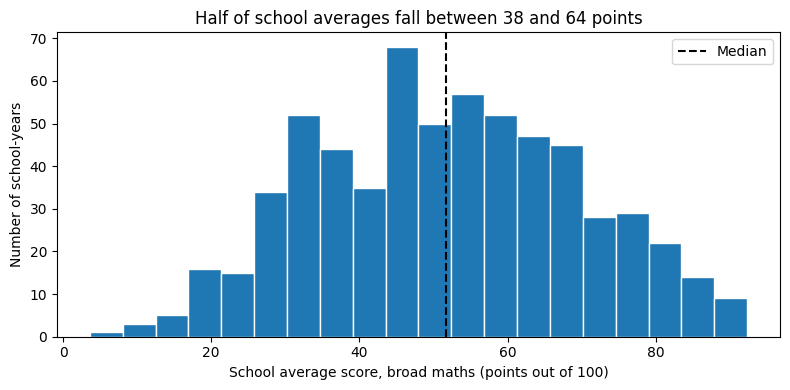

In [52]:
# Histogram: how many school-years fall into each score band
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df_master['average_score'], bins=20, edgecolor='white')

# Dashed line at the median, to show where the middle school lies
ax.axvline(df_master['average_score'].median(), color='black', linestyle='--', label='Median')

# Title states the finding; axis labels name the variable and unit (rules from the slides)
ax.set(title='Half of school averages fall between 38 and 64 points',
       xlabel='School average score, broad maths (points out of 100)',
       ylabel='Number of school-years')
ax.legend()
fig.tight_layout()
plt.show()

School averages are roughly symmetric around 52 points (mean ≈ median), ranging from 3.6 to 92.4. Half of school-years fall between 38 and 64 points. There is no extreme skew, so the mean is a fair summary.

In [53]:
# National average per year, weighted by takers: all students' points / all students.
# Step 1: each school's total points (average x takers), added up per year
points = (df_master['average_score'] * df_master['cohort_size']).groupby(df_master['exam_year']).sum()

# Step 2: divide by all takers per year -> weighted national average
yearly = (points / df_master.groupby('exam_year')['cohort_size'].sum()).to_frame('national_average')

# For comparison: the simple average of school averages (every school counts equally)
yearly['simple_average'] = df_master.groupby('exam_year')['average_score'].mean()
yearly

,national_average,simple_average
exam_year,,
2021,51.044118,45.839283
2022,57.761793,51.888430
2023,61.980446,57.475549
2024,55.407240,48.463736
2025,61.216968,54.513554


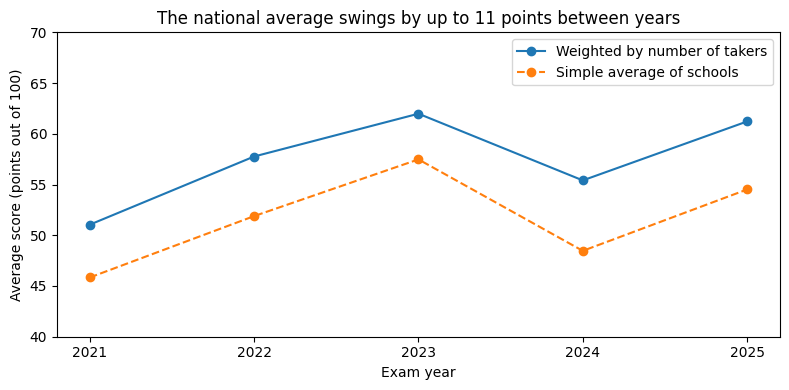

In [54]:
# Line chart: one line per way of averaging, one point per year
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(yearly.index, yearly['national_average'], marker='o', label='Weighted by number of takers')
ax.plot(yearly.index, yearly['simple_average'], marker='o', linestyle='--', label='Simple average of schools')

ax.set_xticks(yearly.index)      # show only whole years on the x-axis (no 2021.5)
ax.set_ylim(40, 70)              # zoom in so the year-to-year swings are visible
ax.set(title='The national average swings by up to 11 points between years',
       xlabel='Exam year', ylabel='Average score (points out of 100)')
ax.legend()
fig.tight_layout()
plt.show()

The weighted national average swings by up to 11 points between years (51.0 in 2021, 62.0 in 2023), most likely because exam difficulty varies. Scores must therefore be compared within the same year (year effects). The weighted line is always 5–7 points above the simple average, which means schools with more takers score higher.

In [55]:
# Year-adjusted score: points above (+) or below (-) the average of the same exam year.
# transform('mean') puts each year's average back on every row of that year,
# so every school can be compared with its own year.
df_master['score_vs_year'] = df_master['average_score'] - df_master.groupby('exam_year')['average_score'].transform('mean')
df_master[['school_name', 'exam_year', 'average_score', 'score_vs_year']].head()

,school_name,exam_year,average_score,score_vs_year
0,''Eduson'' kool,2023,28.833333,-28.642215
1,Abja Gümnaasium,2022,40.000000,-11.888430
2,Abja Gümnaasium,2024,19.833333,-28.630403
3,Abja Gümnaasium,2025,25.600000,-28.913554
4,Antsla Gümnaasium,2021,29.600000,-16.239283


In [56]:
# Public schools only (private schools have no ownership value and are outside our scope)
df_public = df_master[df_master['ownership'].notna()]

# Summary of the year-adjusted score per owner type
df_public.groupby('ownership')['score_vs_year'].describe()

,count,mean,std,min,25%,50%,75%,max
ownership,,,,,,,,
municipal,455.0,-1.219836,17.438160,-43.100549,-14.691981,-2.042684,11.058765,43.308991
state,115.0,5.220549,13.961659,-31.476665,-3.175686,6.295285,14.717999,39.315484


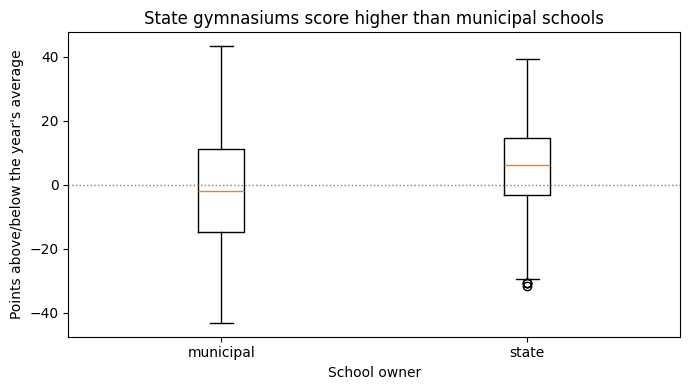

In [57]:
# Box plot: one box per owner type
fig, ax = plt.subplots(figsize=(7, 4))
groups = ['municipal', 'state']
ax.boxplot([df_public.loc[df_public['ownership'] == g, 'score_vs_year'] for g in groups],
           tick_labels=groups)

# Dotted line at 0 = exactly the year's average
ax.axhline(0, color='grey', linestyle=':', linewidth=1)
ax.set(title='State gymnasiums score higher than municipal schools',
       xlabel='School owner',
       ylabel="Points above/below the year's average")
fig.tight_layout()
plt.show()

State gymnasiums score about 6 points above the year’s average (median), municipal schools about 2 below. State schools also vary less. This is an association: state gymnasiums are mostly larger schools in county centres, some with entrance exams, so location, school size and student selection may explain part of the gap.

In [58]:
import numpy as np

# Make a copy so we can add a column without warnings (df_public was filtered from df_master)
df_public = df_public.copy()

# One label per school-year from the two 0/1 flags:
# no Russian takers -> 'Estonian only'; no Estonian takers -> 'Russian only'; otherwise 'Both'
df_public['exam_language_group'] = np.where(
    df_public['take_exam_in_russian'] == 0, 'Estonian only',
    np.where(df_public['take_estonian_exam'] == 0, 'Russian only', 'Both')
)
df_public['exam_language_group'].value_counts()

,count
exam_language_group,
Estonian only,422
Russian only,105
Both,43


                     count      mean        std        min        25%  \
exam_language_group                                                     
Both                  43.0 -6.139679  13.094016 -31.476665 -13.062828   
Estonian only        422.0 -0.929397  17.362172 -43.100549 -14.021191   
Russian only         105.0  6.681424  14.970314 -25.296163  -3.255403   

                          50%        75%        max  
exam_language_group                                  
Both                -6.564836   3.442316  23.193406  
Estonian only       -0.719793  11.139715  43.308991  
Russian only         7.657178  17.204196  34.629303  


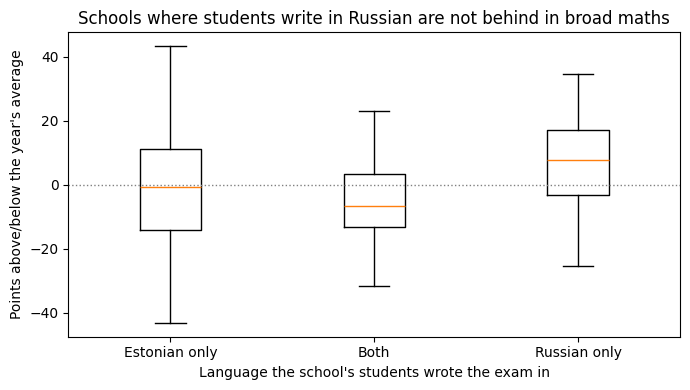

In [59]:
# Year-adjusted score per language group
print(df_public.groupby('exam_language_group')['score_vs_year'].describe())

# Box plot: one box per group
fig, ax = plt.subplots(figsize=(7, 4))
groups = ['Estonian only', 'Both', 'Russian only']
ax.boxplot([df_public.loc[df_public['exam_language_group'] == g, 'score_vs_year'] for g in groups],
           tick_labels=groups)
ax.axhline(0, color='grey', linestyle=':', linewidth=1)
ax.set(title='Schools where students write in Russian are not behind in broad maths',
       xlabel='Language the school\'s students wrote the exam in',
       ylabel="Points above/below the year's average")
fig.tight_layout()
plt.show()

Contrary to our expectation, schools where students write the broad-maths exam in Russian do not score lower (median +7.7 vs −0.7 for Estonian-only schools). At student level, Russian- and Estonian-writing students score within about 3 points of each other in every year. Likely reasons: fewer Russian-writing students choose broad maths (52% vs 65%), so those who do are more selected; and Russian-language schools are mostly larger town schools. Mixed schools (‘Both’) score lowest. This is worth examining in the model. Mixed schools are mostly in Ida-Viru county and towns with large Russian-speaking populations (Jõhvi, Kohtla-Järve, Maardu, Tartu Annelinna), often schools in the middle of the transition to Estonian-language teaching.

In [60]:
# Correlation of each numeric factor with the year-adjusted score:
# +1 = rise together perfectly, 0 = no straight-line relationship, -1 = opposite directions
df_public[['score_vs_year', 'teaching_qualification_ratio', 'median_income', 'cohort_size']].corr()['score_vs_year']

,score_vs_year
score_vs_year,1.000000
teaching_qualification_ratio,0.229177
median_income,0.119348
cohort_size,0.371005


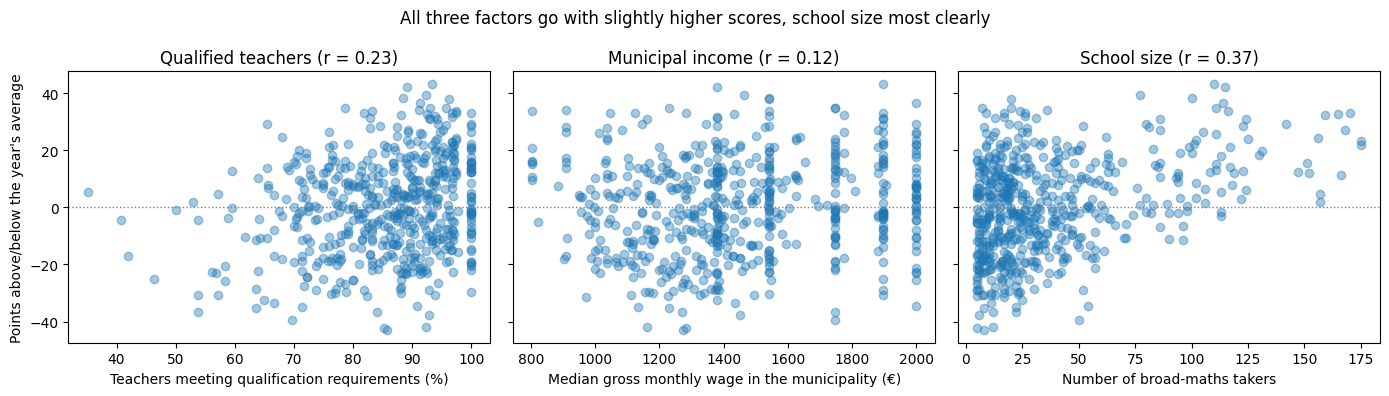

In [61]:
# Three scatter plots side by side, sharing the same y-axis (sharey=True) so they can be compared
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

# axes[0], axes[1], axes[2] are the three plotting areas, left to right
# alpha=0.4 makes dots partly transparent, so overlapping dots show as darker areas
axes[0].scatter(df_public['teaching_qualification_ratio'], df_public['score_vs_year'], alpha=0.4)
axes[0].set(title='Qualified teachers (r = 0.23)', xlabel='Teachers meeting qualification requirements (%)',
            ylabel="Points above/below the year's average")

axes[1].scatter(df_public['median_income'], df_public['score_vs_year'], alpha=0.4)
axes[1].set(title='Municipal income (r = 0.12)', xlabel='Median gross monthly wage in the municipality (€)')

axes[2].scatter(df_public['cohort_size'], df_public['score_vs_year'], alpha=0.4)
axes[2].set(title='School size (r = 0.37)', xlabel='Number of broad-maths takers')

# Dotted zero line on every panel = the year's average
for ax in axes:
    ax.axhline(0, color='grey', linestyle=':', linewidth=1)

# One title over all three panels
fig.suptitle('All three factors go with slightly higher scores, school size most clearly')
fig.tight_layout()
plt.show()

All three factors are positively but weakly associated with the year-adjusted score. School size is the strongest (r = 0.37): small schools vary widely, while large schools mostly score above average. Teacher qualification shows a moderate pattern (r = 0.23): schools with under 70% qualified teachers mostly score below average. Municipal income is weakest (r = 0.12), partly because it is one value per municipality (vertical stripes in the plot, e.g. all Tallinn schools share one value), so it cannot show differences between schools in the same area.

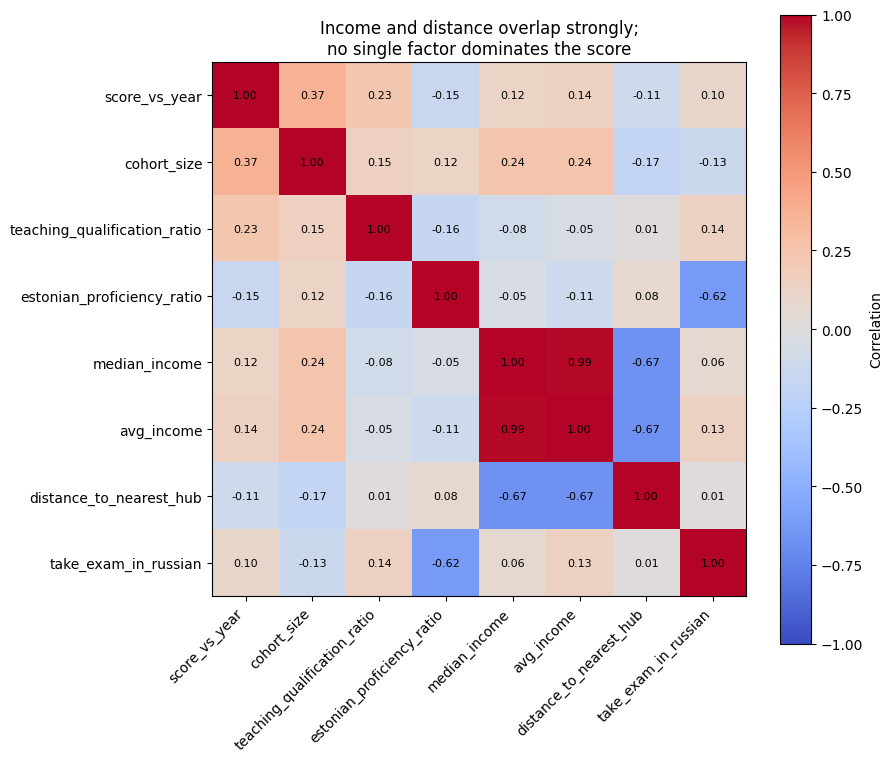

In [62]:
# Columns to compare: the score plus the numeric factors
cols = ['score_vs_year', 'cohort_size', 'teaching_qualification_ratio', 'estonian_proficiency_ratio',
        'median_income', 'avg_income', 'distance_to_nearest_hub', 'take_exam_in_russian']

# Correlation table: every column against every other column
corr = df_public[cols].corr()

fig, ax = plt.subplots(figsize=(9, 8))     # was (8, 7): a bigger figure leaves room for the labels
# imshow draws the table as coloured squares; vmin/vmax fix the colour scale to -1...+1
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

# Column names on both axes; rotation=45 tilts the bottom labels so they don't overlap
ax.set_xticks(range(len(cols)), cols, rotation=45, ha='right')
ax.set_yticks(range(len(cols)), cols)

# Write the correlation value in each square (two loops: rows i, columns j)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)

fig.colorbar(im, ax=ax, label='Correlation')   # colour key on the right
ax.set_title('Income and distance overlap strongly;\nno single factor dominates the score')
fig.tight_layout()
plt.show()

No factor is strongly correlated with the year-adjusted score on its own (strongest: school size 0.37, teacher qualification 0.23; distance −0.11). Several factors overlap: median and average income are almost identical (0.99), so only median income will be used; income and distance to Tallinn/Tartu are strongly related (−0.67); and the share of teachers meeting the Estonian requirement is lower where students write in Russian (−0.62). These overlaps need checking (e.g. VIF) before modelling.

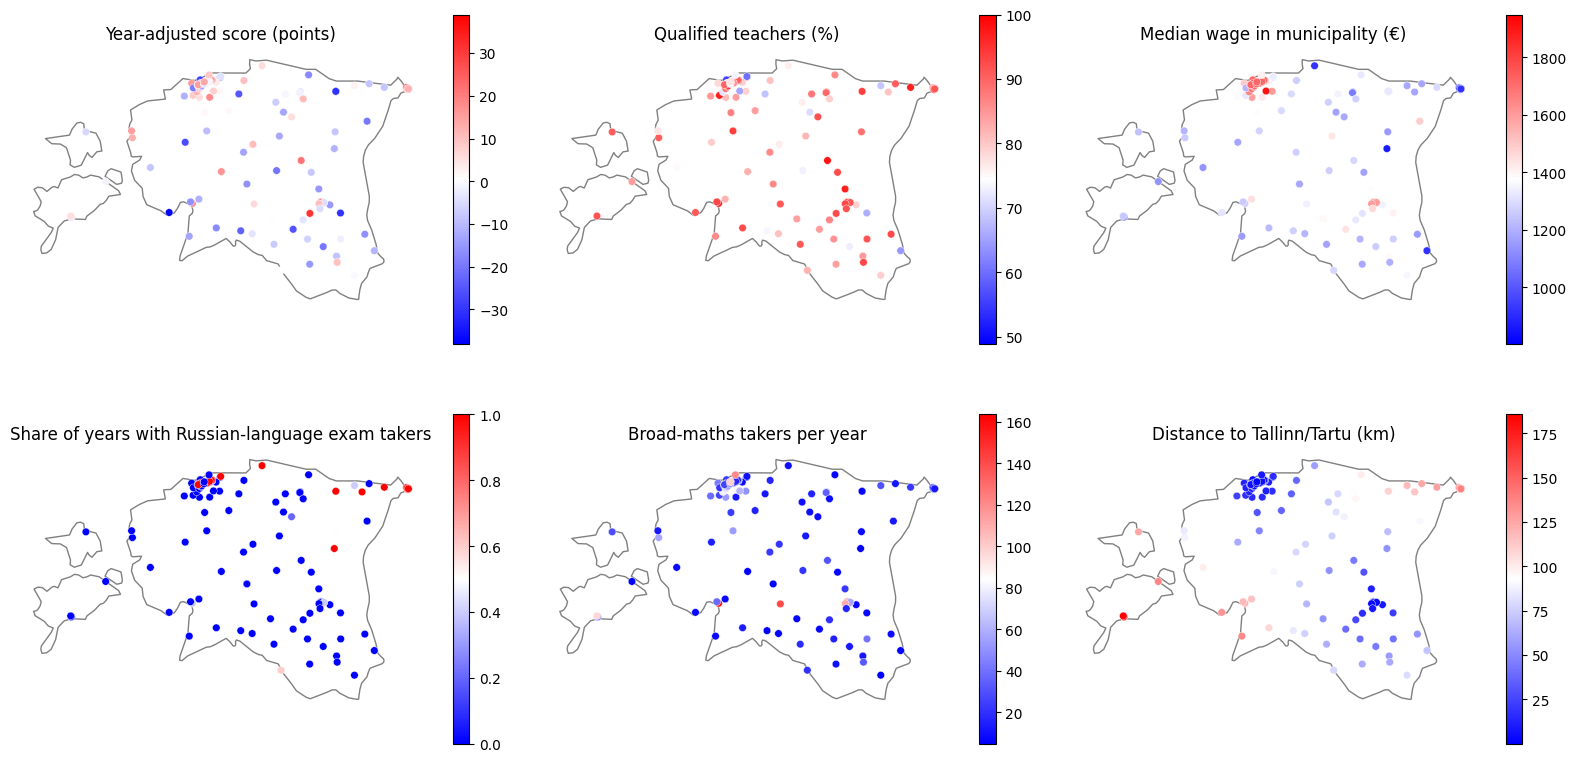

In [74]:
# Maps of Estonia: one dot per public school (mean over 2021-2025)
# Estonia outline as a grey background
world = gpd.read_file("https://naturalearth.s3.amazonaws.com/50m_cultural/ne_50m_admin_0_countries.zip")
estonia = world[world["ADM0_A3"] == "EST"]

# One row per school (average over the years)
school = df_public.groupby("school_name").mean(numeric_only=True)

panels = {
    "score_vs_year": "Year-adjusted score (points)",
    "teaching_qualification_ratio": "Qualified teachers (%)",
    "median_income": "Median wage in municipality (€)",
    "take_exam_in_russian": "Share of years with Russian-language exam takers",
    "cohort_size": "Broad-maths takers per year",
    "distance_to_nearest_hub": "Distance to Tallinn/Tartu (km)",
}

# Draw each map iteratively
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (col, title) in zip(axes.ravel(), panels.items()):
    estonia.plot(ax=ax, color="#FFFFFF", edgecolor="grey")
    d = school.dropna(subset=[col])
    sc = ax.scatter(d["longitude"], d["latitude"], c=d[col], cmap="bwr", s=30, edgecolor="white", linewidth=0.3)
    fig.colorbar(sc, ax=ax, shrink=0.7)
    ax.set_title(title)
    ax.axis("off")

fig.tight_layout()
plt.show()

## EDA summary

**Data.** 626 school-years (155 schools, 2021–2025), broad maths only. 82 school-years with fewer than
5 takers were removed (scores hidden). 56 rows have no ownership or distance (private schools,
outside scope); teacher ratios are missing for 32 rows and income for 12.

**Findings.**
1. School averages are roughly symmetric around 52 points (range 3.6–92.4).
2. The national average swings by up to 11 points between years (51.0 in 2021, 62.0 in 2023),
   so scores must be compared within years. We use a year-adjusted score.
3. Larger schools score higher (r = 0.37); small schools vary the most.
4. State gymnasiums score about 6 points above the year's average, municipal about 2 below.
   This is likely related to location, size and selection, not ownership as such.
5. Contrary to our expectation, schools where students write in Russian do not score lower in broad
   maths; students writing in Russian and Estonian score within about 3 points of each other.
   Fewer Russian-writing students choose broad maths (52% vs 65%), so they are more selected.
   Mixed-language schools, mostly in Ida-Viru, score lowest.
6. Teacher qualification goes with slightly higher scores (r = 0.23); municipal income only weakly
   (r = 0.12), partly because it is one value per municipality.

**Implications for modelling (A3).** Use the year-adjusted score (or year effects); weight by
cohort size; use median income only; check overlap between income and distance, and between
language and the Estonian-requirement share (VIF). All results are associations, not causes.